In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, balanced_accuracy_score
from imblearn.over_sampling import SMOTE
import seaborn as sns
from imblearn.metrics import geometric_mean_score


In [2]:
toxic_data = pd.read_csv('https://raw.githubusercontent.com/krtka2012/qsar_projectML/refs/heads/main/qsar_oral_toxicity.csv', sep=';', header=None)

In [3]:
toxic_data

,0,1,2,3,4,5,6,7,8,9,...,1015,1016,1017,1018,1019,1020,1021,1022,1023,1024
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,negative
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,negative
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,negative
3,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,negative
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8987,0,0,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,negative
8988,0,1,0,0,0,1,0,1,0,0,...,0,0,0,1,0,0,0,0,0,negative
8989,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,negative
8990,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,negative


In [4]:
toxic_data.isnull().sum()

0       0
1       0
2       0
3       0
4       0
       ..
1020    0
1021    0
1022    0
1023    0
1024    0
Length: 1025, dtype: int64

In [5]:
toxic_data[1024].value_counts()

1024
negative    8251
positive     741
Name: count, dtype: int64

In [6]:
toxic_data[1024] = (toxic_data[1024].replace({"negative": 0, "positive": 1}).astype(int))

In [7]:
toxic_data[1024].value_counts()

1024
0    8251
1     741
Name: count, dtype: int64

In [8]:
X = toxic_data.drop(columns=1024)
y = toxic_data[1024]

In [9]:
print(X)
print(y)

      0     1     2     3     4     5     6     7     8     9     ...  1014  \
0        0     0     0     0     0     0     0     0     0     0  ...     0   
1        0     0     1     0     0     0     0     0     0     0  ...     0   
2        0     0     0     0     0     0     0     0     0     0  ...     0   
3        0     0     0     0     0     0     0     1     0     0  ...     0   
4        0     0     0     0     0     0     0     0     0     0  ...     0   
...    ...   ...   ...   ...   ...   ...   ...   ...   ...   ...  ...   ...   
8987     0     0     0     0     0     0     0     1     0     0  ...     0   
8988     0     1     0     0     0     1     0     1     0     0  ...     0   
8989     0     0     0     0     0     0     0     1     0     0  ...     0   
8990     0     0     0     0     0     0     0     0     0     0  ...     0   
8991     0     0     1     0     0     0     0     0     0     0  ...     0   

      1015  1016  1017  1018  1019  1020  1021  102

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [13]:
knn = KNeighborsClassifier(n_neighbors=5)

Accuracy AFTER SMOTE: 93.89 %

Classification Report Before SMOTE:
               precision    recall  f1-score   support

           0       0.95      0.98      0.97      1651
           1       0.68      0.48      0.56       148

    accuracy                           0.94      1799
   macro avg       0.82      0.73      0.77      1799
weighted avg       0.93      0.94      0.93      1799



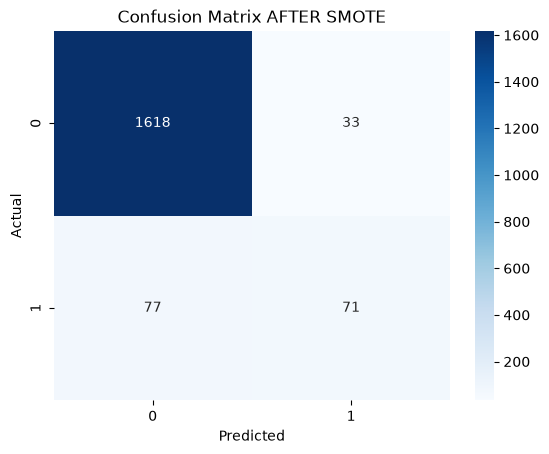

In [ ]:
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("Accuracy BEFORE SMOTE:", round(accuracy_score(y_test, y_pred)*100, 2), "%\n")
print("Classification Report Before SMOTE:\n", classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix AFTER SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [11]:
smote = SMOTE(sampling_strategy='minority', random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

Accuracy AFTER SMOTE: 67.82 %

Classification Report AFTER SMOTE:
               precision    recall  f1-score   support

           0       0.98      0.66      0.79      1651
           1       0.19      0.89      0.31       148

    accuracy                           0.68      1799
   macro avg       0.59      0.77      0.55      1799
weighted avg       0.92      0.68      0.75      1799



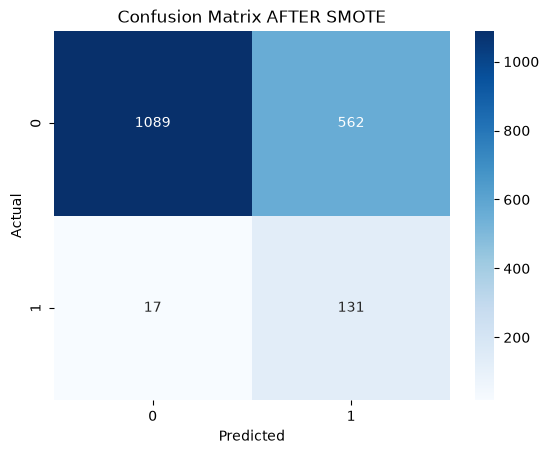

In [ ]:

knn.fit(X_train_sm, y_train_sm)

y_pred_sm = knn.predict(X_test)

print("Accuracy AFTER SMOTE:", round(accuracy_score(y_test, y_pred_sm)*100, 2), "%\n")
print("Classification Report AFTER SMOTE:\n", classification_report(y_test, y_pred_sm))

sns.heatmap(confusion_matrix(y_test, y_pred_sm), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix AFTER SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()